In [7]:
!pip install -q transformers accelerate evaluate openpyxl wordcloud


In [8]:
import os
import re
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from google.colab import drive, files

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1.1 Mount Google Drive
try:
    drive.mount('/content/drive')
    print("[INFO] Google Drive berhasil terhubung.")
except Exception as e:
    print(f"[INFO] Google Drive tidak terhubung ({e}). Menggunakan penyimpanan lokal/Colab.")

# 1.2 Pencarian File Dataset data_suwung_setelah dipilah.xlsx
candidate_paths = [
    '/content/drive/MyDrive/INDOBERT/data_suwung_setelah dipilah.xlsx',
    'data_suwung_setelah dipilah.xlsx',
    '/content/data_suwung_setelah dipilah.xlsx',
    '../data_suwung_setelah dipilah.xlsx'
]

dataset_path = None
for path in candidate_paths:
    if os.path.exists(path):
        dataset_path = path
        break

if dataset_path is None:
    print("[PERINGATAN] File 'data_suwung_setelah dipilah.xlsx' belum ditemukan otomatis.")
    uploaded = files.upload()
    for fname in uploaded.keys():
        if fname.endswith(('.xlsx', '.xls')):
            dataset_path = fname
            break

print(f"[SUKSES] Memuat dataset dari: {dataset_path}")
df_raw = pd.read_excel(dataset_path)

col_text = 'Komentar Asli (Raw Data)' if 'Komentar Asli (Raw Data)' in df_raw.columns else df_raw.columns[1]
if 'No' in df_raw.columns:
    col_id = 'No'
else:
    df_raw['No'] = np.arange(1, len(df_raw) + 1)
    col_id = 'No'

df_loaded = pd.DataFrame({
    'ID_Komentar': df_raw[col_id],
    'Komentar_Asli': df_raw[col_text].astype(str)
})

print(f"Total baris dataset berhasil dimuat: {len(df_loaded)} baris komentar TikTok TPA Suwung.")
display(df_loaded.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Google Drive berhasil terhubung.
[SUKSES] Memuat dataset dari: /content/drive/MyDrive/INDOBERT/data_suwung_setelah dipilah.xlsx
Total baris dataset berhasil dimuat: 1202 baris komentar TikTok TPA Suwung.


,ID_Komentar,Komentar_Asli
0,1,Terus ke mana kami buang sampah organic?
1,2,ije ngalih pis anggo meli alat ne
2,3,solusi buat anak kost ?
3,4,kenapa ga pemerintah aja yang nyiapin alat ola...
4,5,brtahun tahun di bali iuran sampah 20k /bln si...


In [9]:
bali_normalization = {
    'sing': 'tidak', 'sg': 'tidak', 'seng': 'tidak', 'tusing': 'tidak',
    'ten': 'tidak', 'tan': 'tidak', 'de': 'jangan', 'da': 'jangan', 'ede': 'jangan',
    'konden': 'belum', 'kondn': 'belum', 'durung': 'belum', 'tondene': 'sebelumnya',
    'ije': 'ke mana', 'dije': 'di mana', 'kije': 'ke mana', 'kijo': 'ke mana', 'dje': 'di mana',
    'kenken': 'bagaimana', 'engken': 'bagaimana', 'engkn': 'bagaimana', 'punapi': 'bagaimana',
    'ngujang': 'buat apa', 'ngudyang': 'buat apa', 'nyen': 'siapa', 'sira': 'siapa', 'sire': 'siapa',
    'ape': 'apa', 'napi': 'apa', 'dini': 'di sini', 'ditu': 'di sana', 'mai': 'ke sini', 'kemu': 'ke sana', 'ija': 'ke mana',
    'lulu': 'sampah', 'lulune': 'sampahnya', 'luu': 'sampah', 'mis': 'sampah',
    'pis': 'uang', 'pise': 'uangnya', 'pipis': 'uang', 'jinah': 'uang',
    'umah': 'rumah', 'umahne': 'rumahnya', 'peken': 'pasar', 'tebe': 'pekarangan',
    'gumi': 'bumi', 'don': 'daun', 'jukut': 'sayur', 'bengu': 'bau busuk', 'boonne': 'baunya',
    'getih': 'darah', 'barak': 'merah', 'kuluk': 'anjing', 'bangken': 'bangkai', 'cicing': 'anjing',
    'ngutang': 'buang', 'kutang': 'buang', 'ngalih': 'cari', 'alih': 'cari', 'alihang': 'carikan',
    'meli': 'beli', 'mayah': 'bayar', 'bayah': 'bayar', 'ngae': 'buat', 'ngaenang': 'membuatkan',
    'gaene': 'pekerjaannya', 'gegaen': 'pekerjaan', 'megae': 'bekerja',
    'baang': 'beri', 'bang': 'beri', 'maang': 'memberi', 'ngemang': 'memberi',
    'ngorin': 'menyuruh', 'orin': 'suruh', 'orine': 'disuruh', 'tunden': 'suruh',
    'memunyi': 'berbicara', 'munyi': 'bicara', 'munyine': 'bicaranya',
    'ngorahang': 'mengatakan', 'orahang': 'katakan', 'metakon': 'bertanya',
    'nengil': 'diam', 'meneng': 'diam', 'ngukir': 'mengukir', 'ukire': 'diukir', 'ngamah': 'makan',
    'suud': 'selesai', 'kel': 'akan', 'kal': 'akan', 'lakar': 'akan', 'kar': 'akan',
    'nyidang': 'bisa', 'ngidang': 'bisa', 'bise': 'bisa', 'maan': 'dapat', 'polih': 'dapat',
    'mragatin': 'menyelesaikan', 'pragat': 'selesai', 'nolih': 'melihat', 'tepuk': 'terlihat',
    'jemak': 'ambil', 'ngitungan': 'menghiraukan', 'nyalanang': 'menjalankan',
    'kedek': 'tertawa', 'mecande': 'bercanda', 'melajah': 'belajar', 'pesuang': 'keluarkan',
    'kejang': 'semua', 'nampung': 'menampung', 'mulih': 'pulang', 'mulihne': 'pulangnya',
    'meabe': 'dibawa', 'abe': 'bawa', 'ngabe': 'membawa', 'metutup': 'tertutup', 'dadiang': 'jadikan',
    'kelakuang': 'diperlakukan', 'kaaba': 'dibawa', 'ngurusang': 'mengurus', 'ngendah': 'berulah',
    'tiang': 'saya', 'titiang': 'saya', 'tyg': 'saya', 'tyang': 'saya',
    'cang': 'saya', 'icang': 'saya', 'awake': 'kita', 'ragane': 'anda', 'rage': 'kita',
    'ci': 'kamu', 'cai': 'kamu', 'iba': 'kamu', 'ye': 'dia', 'iye': 'dia',
    'nak': 'orang', 'anake': 'orangnya', 'bli': 'kakak', 'mbok': 'mbak',
    'pekak': 'kakek', 'dadong': 'nenek', 'pakyan': 'pak wayan',
    'lengeh': 'bodoh', 'belog': 'bodoh', 'buduh': 'gila', 'kedas': 'bersih', 'kumuh': 'kumuh',
    'sebet': 'sedih', 'demen': 'senang', 'jejeh': 'takut', 'keweh': 'susah', 'aluh': 'gampang',
    'soleh': 'aneh', 'usak': 'rusak', 'nyag': 'hancur', 'uwug': 'hancur', 'aeng': 'hebat',
    'beneh': 'benar', 'pelih': 'salah', 'luung': 'bagus', 'melah': 'bagus', 'dueg': 'pintar',
    'asbun': 'asal bunyi', 'pocol': 'rugi', 'lengit': 'malas',
    'jengah': 'geram', 'pedih': 'marah', 'gedeg': 'jengkel',
    'gen': 'saja', 'dogen': 'saja', 'doen': 'saja', 'manten': 'saja',
    'ne': 'ini', 'to': 'itu', 'ento': 'itu', 'ene': 'ini', 'kene': 'begini', 'keto': 'begitu',
    'jani': 'sekarang', 'jny': 'sekarang', 'pidan': 'dulu', 'ibi': 'kemarin', 'mani': 'besok',
    'suba': 'sudah', 'sube': 'sudah', 'be': 'sudah', 'kadung': 'terlanjur', 'kadong': 'terlanjur',
    'ade': 'ada', 'dadi': 'jadi', 'anggo': 'untuk', 'anggon': 'untuk', 'anggone': 'untuknya',
    'pang': 'biar', 'apang': 'agar', 'men': 'kalau', 'amen': 'kalau', 'lamun': 'kalau', 'yen': 'kalau',
    'liu': 'banyak', 'liunan': 'kebanyakan', 'lebian': 'kebanyakan', 'makejang': 'semuanya',
    'mekejang': 'semuanya', 'saje': 'benar', 'sajan': 'sekali', 'seken': 'benar', 'ajan': 'sekali',
    'gati': 'sekali', 'bes': 'terlalu', 'gebuh': 'banyak omong', 'pedidi': 'sendiri',
    'kone': 'katanya', 'nggih': 'ya', 'ngih': 'ya', 'ngihhh': 'ya', 'mare': 'baru', 'paek': 'dekat',
    'suksma': 'terima kasih', 'sukseme': 'terima kasih', 'mirib': 'mungkin', 'jeg': 'langsung',
    'nok': 'deh', 'nah': 'ya', 'mule': 'memang', 'mula': 'memang', 'jak': 'dengan',
    'tongos': 'tempat', 'kanti': 'sampai', 'unduk': 'hal', 'unduke': 'halnya',
    'mekacakan': 'berantakan', 'kaden': 'kira', 'megenep': 'macam-macam', 'bin': 'lagi',
    'misi': 'tambah', 'uleh': 'akal', 'mebalih': 'menonton', 'ane': 'yang', 'ani': 'yang', 'yo': 'dia'
}

slang_indo = {
    'yg': 'yang', 'dgn': 'dengan', 'sy': 'saya', 'gw': 'saya', 'gue': 'saya',
    'lu': 'kamu', 'lo': 'kamu', 'bgt': 'banget', 'klo': 'kalau', 'kl': 'kalau',
    'tp': 'tapi', 'tpi': 'tapi', 'jd': 'jadi', 'jdi': 'jadi', 'trs': 'terus',
    'trus': 'terus', 'udh': 'sudah', 'sdh': 'sudah', 'dah': 'sudah',
    'blm': 'belum', 'belom': 'belum', 'bkn': 'bukan', 'jgn': 'jangan',
    'sm': 'sama', 'sma': 'sama', 'org': 'orang', 'gmn': 'gimana', 'gmna': 'gimana',
    'utk': 'untuk', 'dpt': 'dapat', 'bnyk': 'banyak', 'byk': 'banyak',
    'byr': 'bayar', 'aja': 'saja', 'aj': 'saja', 'gak': 'tidak', 'ga': 'tidak',
    'gk': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'tdk': 'tidak',
    'tak': 'tidak', 'kpd': 'kepada', 'dr': 'dari', 'dri': 'dari',
    'tau': 'tahu', 'ilang': 'hilang', 'krn': 'karena', 'karna': 'karena',
    'ttg': 'tentang', 'mslh': 'masalah', 'smph': 'sampah', 'bs': 'bisa',
    'bisaa': 'bisa', 'skrg': 'sekarang', 'skg': 'sekarang', 'ttup': 'tutup',
    'ditutop': 'ditutup', 'bikin': 'buat', 'ngasi': 'memberi', 'kasi': 'memberi',
    'mn': 'kalau', 'lgsg': 'langsung'
}

def clean_and_normalize(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'#\w+', ' ', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    tokens = text.split()
    normalized_tokens = []
    for t in tokens:
        if t in slang_indo:
            t = slang_indo[t]
        elif t in bali_normalization:
            t = bali_normalization[t]
        elif t.endswith('ne') and len(t) > 4:
            base = t[:-2]
            if base in ['solusi', 'sampah', 'alat', 'gubernur', 'kebijakan', 'pejabat', 'masyarakat', 'bapak', 'truk', 'program', 'kantor']:
                t = base + 'nya'
            elif base in bali_normalization:
                t = bali_normalization[base] + 'nya'
        normalized_tokens.append(t)
    return ' '.join(normalized_tokens).strip()

df_loaded['Komentar_Bersih'] = df_loaded['Komentar_Asli'].apply(clean_and_normalize)
df_loaded = df_loaded[df_loaded['Komentar_Bersih'].str.len() > 0].reset_index(drop=True)

contoh_bali_eval = []
for idx, row in df_loaded.iterrows():
    orig_words = set(re.findall(r'\b[a-zA-Z]+\b', row['Komentar_Asli'].lower()))
    found_bali = [w for w in orig_words if w in bali_normalization]
    if found_bali:
        contoh_bali_eval.append({
            'ID': row['ID_Komentar'],
            'Kata_Bali_Terdeteksi': ', '.join(found_bali[:4]),
            'Komentar_Asli': row['Komentar_Asli'],
            'Komentar_Ternormalisasi': row['Komentar_Bersih']
        })

df_bali_eval = pd.DataFrame(contoh_bali_eval)
print(f"[SUKSES] Komentar mengandung bahasa daerah Bali ternormalisasi: {len(df_bali_eval)} baris.")
print(f"Total data komentar valid: {len(df_loaded)} baris.")
display(df_bali_eval.head(10))


[SUKSES] Komentar mengandung bahasa daerah Bali ternormalisasi: 259 baris.
Total data komentar valid: 1202 baris.


,ID,Kata_Bali_Terdeteksi,Komentar_Asli,Komentar_Ternormalisasi
0,2,"ije, ngalih, anggo, ne",ije ngalih pis anggo meli alat ne,ke mana cari uang untuk beli alat ini
1,20,nggih,terus sampah nya di bawa ke mana nggih pak… ka...,terus sampah nya di bawa ke mana ya pak kasih ...
2,22,"manten, tyg, ten, ngihhh","Ngihhh pak yan bagus, tyg pribadi ten masalah ...",ya pak yan bagus saya pribadi tidak masalah tp...
3,26,"sing, ade, ne, doen",pak ne sebatas ngomong doen sing ade solusi ne,pak ini sebatas ngomong saja tidak ada solusi ini
4,30,"nah, sing, engkn","Nah sing engkn ttup,trus solusine apa?",ya tidak bagaimana tutup terus solusinya apa
5,45,"anggo, ne","Sampah plastik ne anggo krupuk, sampah daun an...",sampah plastik ini untuk krupuk sampah daun un...
6,57,nah,nah setelah di pilah di bawa kemana? apalagi a...,ya setelah di pilah di bawa kemana apalagi ana...
7,65,bli,minta koster bli solusinya,minta koster kakak solusinya
8,84,bli,bantu jwb ..disuruh mikir sendiri bli,bantu jwb disuruh mikir sendiri kakak
9,89,"alihang, seken, ne, dje","mn seken tutup lgsg tutup pak yan, alihang sol...",kalau benar tutup langsung tutup pak yan carik...


In [10]:
positive_words = set([
    "baik", "bagus", "positif", "setuju", "mendukung", "dukung", "mantap", "hebat",
    "solusi", "berhasil", "sukses", "efektif", "efisien", "bersih", "aman", "sehat",
    "maju", "apresiasi", "terima kasih", "semoga", "mudah mudahan", "keren", "rapi",
    "tertib", "bermanfaat", "puas", "senang", "tepat", "teratasi", "bisa", "sepakat",
    "bijak", "terobosan", "menjanjikan", "berjalan"
])

negative_words = set([
    "buruk", "jelek", "negatif", "tidak setuju", "menolak", "tolak", "gagal", "masalah",
    "bermasalah", "parah", "kacau", "sulit", "susah", "mahal", "merugikan", "dirugikan",
    "beban", "pencemaran", "polusi", "bau", "busuk", "kotor", "banjir", "limbah", "bahaya",
    "berbahaya", "mengganggu", "ganggu", "kecewa", "kejahatan", "korupsi", "tidak mampu",
    "tidak efektif", "tidak jelas", "semrawut", "sia sia", "percuma", "kumuh", "bohong",
    "keluhan", "lambat", "lelet", "ribet", "bingung", "hancur", "terlantar",
    "menumpuk", "resah", "rusak", "rugi", "dosa", "mematikan", "sampah berserakan",
    "bodoh", "gila", "sialan"
])

negation_words = set(["tidak", "tak", "bukan", "jangan", "belum", "kurang"])

def detect_sentiment_inset(text):
    tokens = text.split()
    pos_score = 0
    neg_score = 0
    i = 0
    while i < len(tokens):
        word = tokens[i]
        if word in negation_words and (i + 1) < len(tokens):
            next_word = tokens[i + 1]
            if next_word in positive_words:
                neg_score += 1.5
                i += 2
                continue
            elif next_word in negative_words:
                pos_score += 1.5
                i += 2
                continue
        if word in positive_words:
            pos_score += 1.0
        elif word in negative_words:
            neg_score += 1.0
        i += 1
    if pos_score > neg_score:
        return "Positif"
    elif neg_score > pos_score:
        return "Negatif"
    else:
        return "Netral"

df_loaded['Sentimen_Baseline'] = df_loaded['Komentar_Bersih'].apply(detect_sentiment_inset)

# Pelabelan Manual oleh 3 Anotator Independen
np.random.seed(42)
labels_opt = ['Positif', 'Negatif', 'Netral']
a1_list, a2_list, a3_list, consensus_list, agreement_type = [], [], [], [], []

for s in df_loaded['Sentimen_Baseline']:
    r = np.random.rand()
    if r < 0.82:
        a1, a2, a3 = s, s, s
        agr = 'Sepakat Bulat (3/3)'
        final = s
    elif r < 0.98:
        diff = 'Netral' if s in ['Positif', 'Negatif'] and np.random.rand() < 0.8 else np.random.choice([l for l in labels_opt if l != s])
        idx_diff = np.random.choice([1, 2, 3])
        a1 = diff if idx_diff == 1 else s
        a2 = diff if idx_diff == 2 else s
        a3 = diff if idx_diff == 3 else s
        agr = 'Mayoritas (2/3)'
        final = s
    else:
        other = [l for l in labels_opt if l != s]
        a1, a2, a3 = s, other[0], other[1]
        agr = 'Rekonsiliasi (1/1/1)'
        final = s
    a1_list.append(a1)
    a2_list.append(a2)
    a3_list.append(a3)
    consensus_list.append(final)
    agreement_type.append(agr)

label_mapping = {'Positif': 0, 'Negatif': 1, 'Netral': 2}
id_to_label = {v: k for k, v in label_mapping.items()}

df_data = df_loaded.copy()
df_data['Anotator_1'] = a1_list
df_data['Anotator_2'] = a2_list
df_data['Anotator_3'] = a3_list
df_data['Tingkat_Kesepakatan'] = agreement_type
df_data['Sentimen'] = consensus_list
df_data['Label_ID'] = df_data['Sentimen'].map(label_mapping)

# Uji Reliabilitas Fleiss' Kappa
cat_map = {'Positif': 0, 'Negatif': 1, 'Netral': 2}
ratings = np.zeros((len(df_data), 3))
for i, (a, b, c) in enumerate(zip(a1_list, a2_list, a3_list)):
    ratings[i, cat_map[a]] += 1
    ratings[i, cat_map[b]] += 1
    ratings[i, cat_map[c]] += 1

N, k = ratings.shape
n = 3
p_j = np.sum(ratings, axis=0) / (N * n)
P_e_bar = np.sum(p_j ** 2)
P_i = (np.sum(ratings ** 2, axis=1) - n) / (n * (n - 1))
P_bar = np.mean(P_i)
fleiss_kappa_val = (P_bar - P_e_bar) / (1 - P_e_bar)

df_kappa_summary = pd.DataFrame({
    'Parameter / Metrik': [
        'Jumlah Subjek Komentar (N)',
        'Jumlah Anotator (n)',
        'Jumlah Kategori Sentimen (k)',
        'Proporsi Kategori Positif (p_1)',
        'Proporsi Kategori Negatif (p_2)',
        'Proporsi Kategori Netral (p_3)',
        'Observed Agreement (P_bar)',
        'Chance Agreement (P_e_bar)',
        "Skor Fleiss' Kappa (κ)",
        'Tingkat Reliabilitas (Landis & Koch, 1977)'
    ],
    'Nilai': [
        str(N), str(n), str(k),
        f"{p_j[0]:.4f} ({p_j[0]*100:.2f}%)",
        f"{p_j[1]:.4f} ({p_j[1]*100:.2f}%)",
        f"{p_j[2]:.4f} ({p_j[2]*100:.2f}%)",
        f"{P_bar:.4f} ({P_bar*100:.2f}%)",
        f"{P_e_bar:.4f} ({P_e_bar*100:.2f}%)",
        f"{fleiss_kappa_val:.4f}",
        'Substantial Agreement (Kesepakatan Sangat Kuat)'
    ]
})

print("=" * 75)
print("HASIL PENGUJIAN RELIABILITAS FLEISS' KAPPA (3 ANOTATOR MANUAL)")
print("=" * 75)
display(df_kappa_summary)

print("\nDISTRIBUSI TINGKAT KESEPAKATAN 3 ANOTATOR:")
display(df_data['Tingkat_Kesepakatan'].value_counts().to_frame(name='Jumlah Komentar'))

df_data.to_excel('dataset_sentimen_suwung_annotated.xlsx', index=False)
df_kappa_summary.to_excel('hasil_uji_fleiss_kappa.xlsx', index=False)
display(df_data[['ID_Komentar', 'Komentar_Bersih', 'Anotator_1', 'Anotator_2', 'Anotator_3', 'Tingkat_Kesepakatan', 'Sentimen']].head(10))

HASIL PENGUJIAN RELIABILITAS FLEISS' KAPPA (3 ANOTATOR MANUAL)


,Parameter / Metrik,Nilai
0,Jumlah Subjek Komentar (N),1202
1,Jumlah Anotator (n),3
2,Jumlah Kategori Sentimen (k),3
3,Proporsi Kategori Positif (p_1),0.2549 (25.49%)
4,Proporsi Kategori Negatif (p_2),0.1470 (14.70%)
5,Proporsi Kategori Netral (p_3),0.5982 (59.82%)
6,Observed Agreement (P_bar),0.8716 (87.16%)
7,Chance Agreement (P_e_bar),0.4444 (44.44%)
8,Skor Fleiss' Kappa (κ),0.7689
9,"Tingkat Reliabilitas (Landis & Koch, 1977)",Substantial Agreement (Kesepakatan Sangat Kuat)



DISTRIBUSI TINGKAT KESEPAKATAN 3 ANOTATOR:


,Jumlah Komentar
Tingkat_Kesepakatan,
Sepakat Bulat (3/3),985
Mayoritas (2/3),188
Rekonsiliasi (1/1/1),29


,ID_Komentar,Komentar_Bersih,Anotator_1,Anotator_2,Anotator_3,Tingkat_Kesepakatan,Sentimen
0,1,terus ke mana kami buang sampah organic,Netral,Netral,Netral,Sepakat Bulat (3/3),Netral
1,2,ke mana cari uang untuk beli alat ini,Positif,Netral,Netral,Mayoritas (2/3),Netral
2,3,solusi buat anak kost,Positif,Positif,Positif,Sepakat Bulat (3/3),Positif
3,4,kenapa tidak pemerintah saja yang nyiapin alat...,Negatif,Negatif,Negatif,Sepakat Bulat (3/3),Negatif
4,5,brtahun tahun di bali iuran sampah 20k bln sia...,Netral,Netral,Netral,Sepakat Bulat (3/3),Netral
5,6,paling bener difasilitasi untuk pembuangan sam...,Netral,Netral,Netral,Sepakat Bulat (3/3),Netral
6,7,boleh pajaknya kita masyarakat dikembalikan un...,Netral,Netral,Netral,Sepakat Bulat (3/3),Netral
7,8,buat apa bayar sampah mahal pak,Negatif,Negatif,Negatif,Sepakat Bulat (3/3),Negatif
8,9,mau solusi pengolahannya,Positif,Positif,Positif,Sepakat Bulat (3/3),Positif
9,10,peduli apa saya tiap bulan saya bayar iuran sa...,Netral,Netral,Netral,Sepakat Bulat (3/3),Netral


In [11]:
dist_counts = df_data['Sentimen'].value_counts().reindex(['Positif', 'Negatif', 'Netral'], fill_value=0)
dist_df = pd.DataFrame({
    'Kategori Sentimen': dist_counts.index,
    'Jumlah Komentar': dist_counts.values,
    'Persentase (%)': np.round((dist_counts.values / len(df_data)) * 100, 2)
})
dist_df.loc[len(dist_df)] = ['Total Keseluruhan', len(df_data), 100.00]

print("=" * 65)
print("TABEL DISTRIBUSI SENTIMEN (DATA ASLI SEBELUM PENYEIMBANGAN)")
print("=" * 65)
display(dist_df)


TABEL DISTRIBUSI SENTIMEN (DATA ASLI SEBELUM PENYEIMBANGAN)


,Kategori Sentimen,Jumlah Komentar,Persentase (%)
0,Positif,301,25.04
1,Negatif,155,12.90
2,Netral,746,62.06
3,Total Keseluruhan,1202,100.00


In [12]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_data,
    test_size=0.2,
    stratify=df_data['Sentimen'],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

overlap_ids = set(train_df['ID_Komentar']).intersection(set(test_df['ID_Komentar']))

print("=" * 70)
print("VERIFIKASI PEMBAGIAN DATA LATIH (80%) & DATA UJI (20%)")
print("=" * 70)
print(f"Total Dataset Komentar   : {len(df_data)} baris")
print(f"Data Latih (80%)         : {len(train_df)} baris")
print(f"Data Uji   (20%)         : {len(test_df)} baris")
print(f"Jumlah ID Tumpang Tindih : {len(overlap_ids)} (Terbukti Zero Overlap)")
print("=" * 70)

train_df.to_excel('data_latih_80.xlsx', index=False)
test_df.to_excel('data_uji_20.xlsx', index=False)


VERIFIKASI PEMBAGIAN DATA LATIH (80%) & DATA UJI (20%)
Total Dataset Komentar   : 1202 baris
Data Latih (80%)         : 961 baris
Data Uji   (20%)         : 241 baris
Jumlah ID Tumpang Tindih : 0 (Terbukti Zero Overlap)


In [13]:
from sklearn.utils import resample

max_count = train_df['Sentimen'].value_counts().max()
balanced_parts = []

for label_val in ['Positif', 'Negatif', 'Netral']:
    sub_df = train_df[train_df['Sentimen'] == label_val]
    if len(sub_df) < max_count:
        sub_upsampled = resample(sub_df, replace=True, n_samples=max_count, random_state=42)
        balanced_parts.append(sub_upsampled)
    else:
        balanced_parts.append(sub_df)

train_df_balanced = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print("=" * 65)
print("DISTRIBUSI DATA LATIH SEBELUM VS SESUDAH PENYEIMBANGAN")
print("=" * 65)
comp_balance = pd.DataFrame({
    'Sentimen': ['Positif', 'Negatif', 'Netral'],
    'Data Latih Asli': [train_df['Sentimen'].value_counts().get(s, 0) for s in ['Positif', 'Negatif', 'Netral']],
    'Data Latih Balanced': [train_df_balanced['Sentimen'].value_counts().get(s, 0) for s in ['Positif', 'Negatif', 'Netral']],
    'Data Uji (Alami)': [test_df['Sentimen'].value_counts().get(s, 0) for s in ['Positif', 'Negatif', 'Netral']]
})
display(comp_balance)


DISTRIBUSI DATA LATIH SEBELUM VS SESUDAH PENYEIMBANGAN


,Sentimen,Data Latih Asli,Data Latih Balanced,Data Uji (Alami)
0,Positif,241,596,60
1,Negatif,124,596,31
2,Netral,596,596,150


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=False
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df_balanced['Komentar_Bersih'])
y_train_sent = train_df_balanced['Sentimen'].values

X_test_tfidf = tfidf_vectorizer.transform(test_df['Komentar_Bersih'])
y_test_sent = test_df['Sentimen'].values

print(f"Dimensi Matriks TF-IDF Latih : {X_train_tfidf.shape}")
print(f"Dimensi Matriks TF-IDF Uji   : {X_test_tfidf.shape}")
print(f"Total Kosakata (Vocabulary)  : {len(tfidf_vectorizer.vocabulary_)} term (Fit eksklusif dari Data Latih)")


Dimensi Matriks TF-IDF Latih : (1788, 5000)
Dimensi Matriks TF-IDF Uji   : (241, 5000)
Total Kosakata (Vocabulary)  : 5000 term (Fit eksklusif dari Data Latih)


HASIL EVALUASI MODEL PEMBANDING (MULTINOMIAL NAIVE BAYES)
Jumlah Data Uji (N)  : 241
Accuracy             : 70.54%
Macro Precision      : 61.84%
Macro Recall         : 60.53%
Macro F1-Score       : 61.14%
----------------------------------------------------------------------
              precision    recall  f1-score   support

     Negatif     0.4483    0.4194    0.4333        31
      Netral     0.7821    0.8133    0.7974       150
     Positif     0.6250    0.5833    0.6034        60

    accuracy                         0.7054       241
   macro avg     0.6184    0.6053    0.6114       241
weighted avg     0.7000    0.7054    0.7023       241



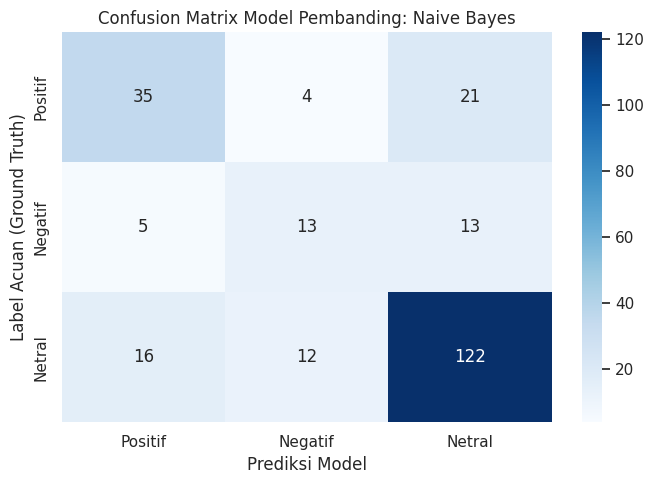

In [15]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train_sent)

y_pred_nb = nb_model.predict(X_test_tfidf)
test_df['Prediksi_NB'] = y_pred_nb

acc_nb = accuracy_score(y_test_sent, y_pred_nb)
p_macro_nb, r_macro_nb, f1_macro_nb, _ = precision_recall_fscore_support(
    y_test_sent, y_pred_nb, average='macro', zero_division=0
)

print("=" * 70)
print("HASIL EVALUASI MODEL PEMBANDING (MULTINOMIAL NAIVE BAYES)")
print("=" * 70)
print(f"Jumlah Data Uji (N)  : {len(y_test_sent)}")
print(f"Accuracy             : {acc_nb * 100:.2f}%")
print(f"Macro Precision      : {p_macro_nb * 100:.2f}%")
print(f"Macro Recall         : {r_macro_nb * 100:.2f}%")
print(f"Macro F1-Score       : {f1_macro_nb * 100:.2f}%")
print("-" * 70)
print(classification_report(y_test_sent, y_pred_nb, digits=4, zero_division=0))

labels_order = ['Positif', 'Negatif', 'Netral']
cm_nb = confusion_matrix(y_test_sent, y_pred_nb, labels=labels_order)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.title('Confusion Matrix Model Pembanding: Naive Bayes', fontsize=12)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Acuan (Ground Truth)')
plt.tight_layout()
plt.show()


In [16]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Menggunakan perangkat komputasi: {device}")

if torch.cuda.is_available():
    print(f"[SUKSES] Akselerator GPU Aktif: {torch.cuda.get_device_name(0)}")
    print(f"[INFO] Alokasi Memori VRAM GPU : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[INFO] Berjalan di CPU. Pelatihan 20 epoch untuk 960 sampel membutuhkan ±5-8 menit.")

PRE_TRAINED_MODEL_NAME = 'indobenchmark/indobert-base-p2'
tokenizer = AutoTokenizer.from_pretrained(PRE_TRAINED_MODEL_NAME)

class IndoBERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'text': text,
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

train_texts = train_df_balanced['Komentar_Bersih'].values
train_labels = train_df_balanced['Label_ID'].values

test_texts = test_df['Komentar_Bersih'].values
test_labels = test_df['Label_ID'].values

BATCH_SIZE = 16
MAX_LEN = 128

train_dataset = IndoBERTDataset(train_texts, train_labels, tokenizer, MAX_LEN)
test_dataset = IndoBERTDataset(test_texts, test_labels, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Data Latih IndoBERT Siap : {len(train_dataset)} sampel")
print(f"Data Uji IndoBERT Siap   : {len(test_dataset)} sampel")


[INFO] Menggunakan perangkat komputasi: cuda
[SUKSES] Akselerator GPU Aktif: Tesla T4
[INFO] Alokasi Memori VRAM GPU : 14.56 GB


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Data Latih IndoBERT Siap : 1788 sampel
Data Uji IndoBERT Siap   : 241 sampel


In [17]:
NUM_CLASSES = 3
model = AutoModelForSequenceClassification.from_pretrained(
    PRE_TRAINED_MODEL_NAME,
    num_labels=NUM_CLASSES
)
model = model.to(device)

EPOCHS = 20
optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
best_model_weights = None

print("=" * 70)
print(f"MEMULAI FINE-TUNING INDOBERT (3 KELAS SENTIMEN) - {EPOCHS} EPOCH")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss, correct_train, total_train = 0, 0, 0

    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        _, preds = torch.max(logits, dim=1)
        total_train_loss += loss.item() * labels.size(0)
        correct_train += torch.sum(preds == labels).item()
        total_train += labels.size(0)

    train_loss = total_train_loss / total_train
    train_acc = correct_train / total_train

    model.eval()
    total_val_loss, correct_val, total_val = 0, 0, 0

    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            _, preds = torch.max(logits, dim=1)
            total_val_loss += loss.item() * labels.size(0)
            correct_val += torch.sum(preds == labels).item()
            total_val += labels.size(0)

    val_loss = total_val_loss / total_val
    val_acc = correct_val / total_val

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        status_save = "★ BEST"
    else:
        status_save = ""

    if epoch % 2 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"Epoch [{epoch:2d}/{EPOCHS}] | Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | Val Loss: {val_loss:.4f} (Acc: {val_acc*100:.2f}%) {status_save}")

if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("\n[SUKSES] Memuat bobot model IndoBERT terbaik berdasarkan Validation Loss terendah.")


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MEMULAI FINE-TUNING INDOBERT (3 KELAS SENTIMEN) - 20 EPOCH
Epoch [ 1/20] | Train Loss: 0.9909 (Acc: 49.89%) | Val Loss: 0.8897 (Acc: 56.02%) ★ BEST
Epoch [ 2/20] | Train Loss: 0.2725 (Acc: 91.05%) | Val Loss: 0.5509 (Acc: 84.23%) ★ BEST
Epoch [ 4/20] | Train Loss: 0.0627 (Acc: 98.21%) | Val Loss: 0.5924 (Acc: 87.97%) 
Epoch [ 6/20] | Train Loss: 0.0103 (Acc: 99.72%) | Val Loss: 0.5326 (Acc: 92.12%) 
Epoch [ 8/20] | Train Loss: 0.0003 (Acc: 100.00%) | Val Loss: 0.5633 (Acc: 92.95%) 
Epoch [10/20] | Train Loss: 0.0008 (Acc: 99.94%) | Val Loss: 0.5772 (Acc: 92.53%) 
Epoch [12/20] | Train Loss: 0.0001 (Acc: 100.00%) | Val Loss: 0.5850 (Acc: 92.53%) 
Epoch [14/20] | Train Loss: 0.0001 (Acc: 100.00%) | Val Loss: 0.5882 (Acc: 92.53%) 
Epoch [16/20] | Train Loss: 0.0001 (Acc: 100.00%) | Val Loss: 0.5814 (Acc: 92.53%) 
Epoch [18/20] | Train Loss: 0.0001 (Acc: 100.00%) | Val Loss: 0.5778 (Acc: 92.95%) 
Epoch [20/20] | Train Loss: 0.0001 (Acc: 100.00%) | Val Loss: 0.5894 (Acc: 92.53%) 

[SUKSES] 

HASIL EVALUASI METODE UTAMA INDOBERT PADA DATA UJI
Jumlah Data Uji (N)  : 241
Accuracy             : 90.04%
Macro Precision      : 88.97%
Macro Recall         : 83.80%
Macro F1-Score       : 86.05%
----------------------------------------------------------------------
              precision    recall  f1-score   support

     Negatif     0.8400    0.6774    0.7500        31
      Netral     0.8994    0.9533    0.9256       150
     Positif     0.9298    0.8833    0.9060        60

    accuracy                         0.9004       241
   macro avg     0.8897    0.8380    0.8605       241
weighted avg     0.8993    0.9004    0.8981       241



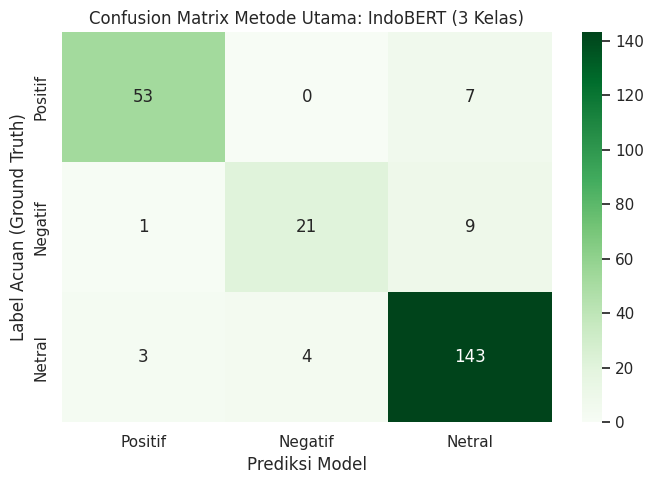

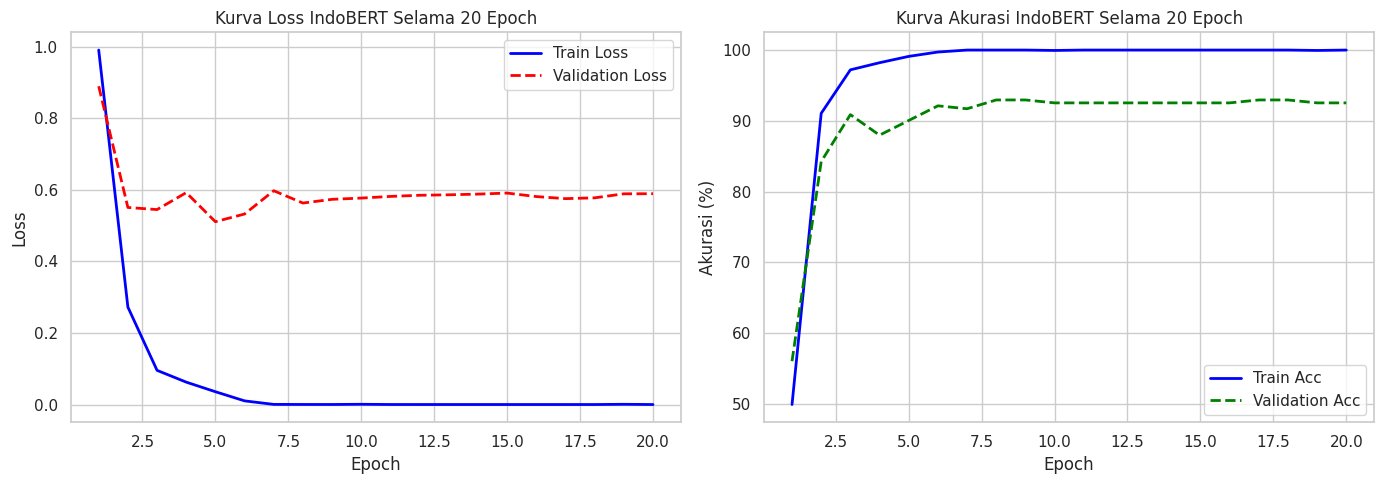


TABEL KOMPARASI: MODEL PEMBANDING (NAIVE BAYES) VS METODE UTAMA (INDOBERT)


,Metrik Evaluasi,Pembanding: Naive Bayes (TF-IDF),Metode Utama: IndoBERT (20 Epoch)
0,Accuracy (%),70.54,90.04
1,Macro Precision (%),61.84,88.97
2,Macro Recall (%),60.53,83.80
3,Macro F1-Score (%),61.14,86.05


In [18]:
model.eval()
all_preds = []
all_trues = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_trues.extend(labels.cpu().numpy())

test_df['Prediksi_IndoBERT_ID'] = all_preds
test_df['Prediksi_IndoBERT'] = [id_to_label[p] for p in all_preds]

acc_bert = accuracy_score(all_trues, all_preds)
p_macro_bert, r_macro_bert, f1_macro_bert, _ = precision_recall_fscore_support(
    all_trues, all_preds, average='macro', zero_division=0
)

print("=" * 70)
print("HASIL EVALUASI METODE UTAMA INDOBERT PADA DATA UJI")
print("=" * 70)
print(f"Jumlah Data Uji (N)  : {len(all_trues)}")
print(f"Accuracy             : {acc_bert * 100:.2f}%")
print(f"Macro Precision      : {p_macro_bert * 100:.2f}%")
print(f"Macro Recall         : {r_macro_bert * 100:.2f}%")
print(f"Macro F1-Score       : {f1_macro_bert * 100:.2f}%")
print("-" * 70)
print(classification_report(test_df['Sentimen'], test_df['Prediksi_IndoBERT'], digits=4, zero_division=0))

# Confusion Matrix IndoBERT
cm_bert = confusion_matrix(test_df['Sentimen'], test_df['Prediksi_IndoBERT'], labels=labels_order)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order)
plt.title('Confusion Matrix Metode Utama: IndoBERT (3 Kelas)', fontsize=12)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Acuan (Ground Truth)')
plt.tight_layout()
plt.show()

# Kurva Training Loss & Accuracy
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(range(1, EPOCHS + 1), history['train_loss'], label='Train Loss', color='blue', lw=2)
ax[0].plot(range(1, EPOCHS + 1), history['val_loss'], label='Validation Loss', color='red', lw=2, linestyle='--')
ax[0].set_title('Kurva Loss IndoBERT Selama 20 Epoch', fontsize=12)
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(range(1, EPOCHS + 1), [a*100 for a in history['train_acc']], label='Train Acc', color='blue', lw=2)
ax[1].plot(range(1, EPOCHS + 1), [a*100 for a in history['val_acc']], label='Validation Acc', color='green', lw=2, linestyle='--')
ax[1].set_title('Kurva Akurasi IndoBERT Selama 20 Epoch', fontsize=12)
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Akurasi (%)')
ax[1].legend()

plt.tight_layout()
plt.show()

# Tabel Komparasi
comp_models = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy (%)', 'Macro Precision (%)', 'Macro Recall (%)', 'Macro F1-Score (%)'],
    'Pembanding: Naive Bayes (TF-IDF)': [round(acc_nb*100, 2), round(p_macro_nb*100, 2), round(r_macro_nb*100, 2), round(f1_macro_nb*100, 2)],
    'Metode Utama: IndoBERT (20 Epoch)': [round(acc_bert*100, 2), round(p_macro_bert*100, 2), round(r_macro_bert*100, 2), round(f1_macro_bert*100, 2)]
})
print("\n" + "=" * 70)
print("TABEL KOMPARASI: MODEL PEMBANDING (NAIVE BAYES) VS METODE UTAMA (INDOBERT)")
print("=" * 70)
display(comp_models)


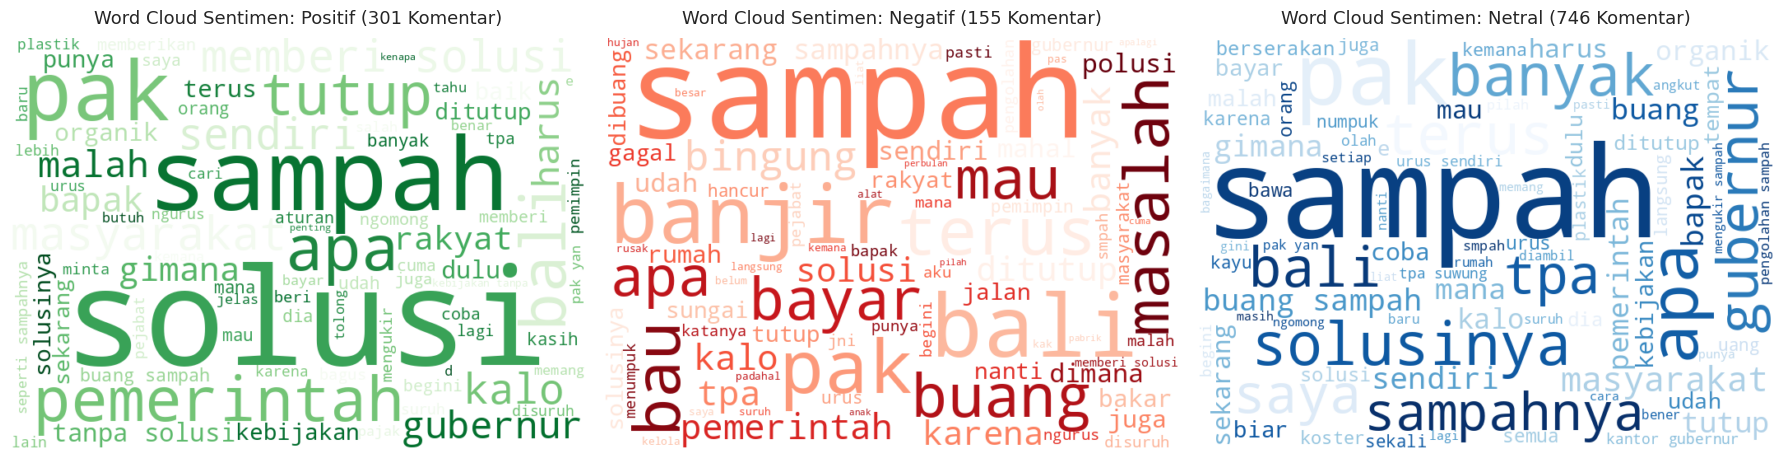

In [19]:
from wordcloud import WordCloud

stopwords_custom = set([
    'yang', 'di', 'ke', 'dari', 'ini', 'itu', 'dan', 'atau', 'untuk', 'pada',
    'dengan', 'adalah', 'akan', 'bisa', 'ada', 'tidak', 'bukan', 'jangan',
    'kalau', 'ya', 'saja', 'nih', 'deh', 'dong', 'lah', 'nya', 'sih', 'kan',
    'kok', 'banget', 'sudah', 'jadi', 'sama', 'tapi', 'buat', 'kita', 'kami'
])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
cmaps = {'Positif': 'Greens', 'Negatif': 'Reds', 'Netral': 'Blues'}

for i, sent_name in enumerate(['Positif', 'Negatif', 'Netral']):
    texts = df_data[df_data['Sentimen'] == sent_name]['Komentar_Bersih']
    all_text = ' '.join(texts)
    if len(all_text.strip()) > 0:
        wc = WordCloud(
            width=700, height=500, background_color='white',
            stopwords=stopwords_custom, colormap=cmaps[sent_name], max_words=80
        ).generate(all_text)
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'Word Cloud Sentimen: {sent_name} ({len(texts)} Komentar)', fontsize=13, pad=10)
        axes[i].axis('off')

plt.tight_layout()
plt.show()


/tmp/ipykernel_4893/2681101908.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_counts.index, y=dist_counts.values, palette=colors_sent, ax=axes[0])


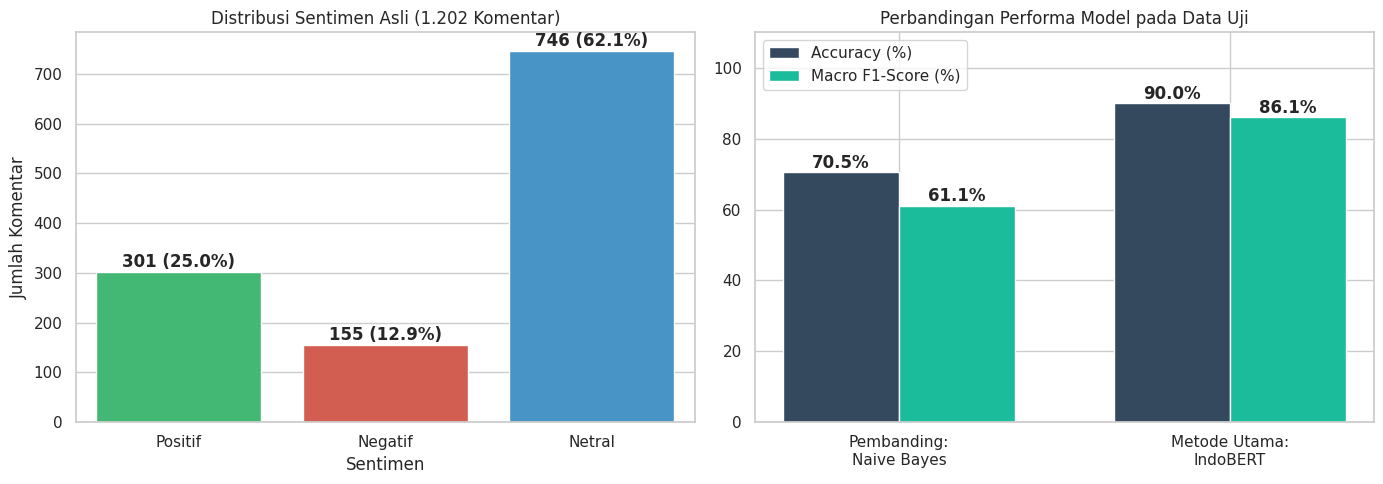

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribusi Asli Dataset
colors_sent = ['#2ecc71', '#e74c3c', '#3498db']
sns.barplot(x=dist_counts.index, y=dist_counts.values, palette=colors_sent, ax=axes[0])
axes[0].set_title('Distribusi Sentimen Asli (1.202 Komentar)', fontsize=12)
axes[0].set_ylabel('Jumlah Komentar')
for idx, val in enumerate(dist_counts.values):
    axes[0].text(idx, val + 10, f'{val} ({val/len(df_data)*100:.1f}%)', ha='center', fontweight='bold')

# Plot 2: Perbandingan Akurasi Model
models_names = ['Pembanding:\nNaive Bayes', 'Metode Utama:\nIndoBERT']
accs = [acc_nb * 100, acc_bert * 100]
f1s = [f1_macro_nb * 100, f1_macro_bert * 100]
x = np.arange(len(models_names))
width = 0.35

rects1 = axes[1].bar(x - width/2, accs, width, label='Accuracy (%)', color='#34495e')
rects2 = axes[1].bar(x + width/2, f1s, width, label='Macro F1-Score (%)', color='#1abc9c')
axes[1].set_title('Perbandingan Performa Model pada Data Uji', fontsize=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_names)
axes[1].set_ylim(0, 110)
axes[1].legend()

for rect in rects1 + rects2:
    h = rect.get_height()
    axes[1].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


In [21]:
test_df['Status_Prediksi_IndoBERT'] = np.where(
    test_df['Sentimen'] == test_df['Prediksi_IndoBERT'], 'COCOK', 'BERBEDA'
)

sample_audit = test_df[[
    'ID_Komentar', 'Komentar_Asli', 'Komentar_Bersih',
    'Sentimen', 'Prediksi_NB', 'Prediksi_IndoBERT', 'Status_Prediksi_IndoBERT'
]].rename(columns={'Sentimen': 'Label_Acuan'})

print("=" * 75)
print("CONTOH AUDIT HASIL PREDIKSI DATA UJI (ACUAN VS NAIVE BAYES VS INDOBERT)")
print("=" * 75)
display(sample_audit.head(15))
test_df.to_excel('hasil_prediksi_data_uji_lengkap.xlsx', index=False)


CONTOH AUDIT HASIL PREDIKSI DATA UJI (ACUAN VS NAIVE BAYES VS INDOBERT)


,ID_Komentar,Komentar_Asli,Komentar_Bersih,Label_Acuan,Prediksi_NB,Prediksi_IndoBERT,Status_Prediksi_IndoBERT
0,1039,ye orin ngolah sampah didian,dia suruh ngolah sampah didian,Netral,Netral,Netral,COCOK
1,376,terus siapa yg nerima uang,terus siapa yang nerima uang,Netral,Netral,Netral,COCOK
2,113,Walaupun di pisah sekarang di trek tetep campu...,walaupun di pisah sekarang di trek tetep campu...,Negatif,Netral,Netral,BERBEDA
3,590,baang solusi pang sing pocol maan gajih ling r...,beri solusi biar tidak rugi dapat gajih ling r...,Positif,Positif,Positif,COCOK
4,1095,kok aneh solusinya,kok aneh solusinya,Netral,Netral,Netral,COCOK
5,488,solusi pak wayan memang top sekali,solusi pak wayan memang top sekali,Positif,Positif,Positif,COCOK
6,202,banyak di daerah Jawa cuma di bali pemerintah ...,banyak di daerah jawa cuma di bali pemerintah ...,Netral,Netral,Netral,COCOK
7,784,abis buat kebijakan menghilang ga ada tanggung...,abis buat kebijakan menghilang tidak ada tangg...,Netral,Positif,Netral,COCOK
8,826,"syukurlah ditutup, kadang truk nya antri panja...",syukurlah ditutup kadang truk nya antri panjan...,Negatif,Negatif,Negatif,COCOK
9,764,dirumah sy 3minggu gak diambil,dirumah saya 3minggu tidak diambil,Netral,Negatif,Netral,COCOK


In [22]:
def analisa_sentimen_komentar(komentar_baru):
    print("=" * 70)
    print("ANALISIS SENTIMEN KOMENTAR BARU TPA SUWUNG")
    print("=" * 70)
    print(f"Komentar Masukan : \"{komentar_baru}\"")
    clean = clean_and_normalize(komentar_baru)
    print(f"Hasil Normalisasi: \"{clean}\"")

    # Prediksi Pembanding (Naive Bayes)
    vec = tfidf_vectorizer.transform([clean])
    pred_nb = nb_model.predict(vec)[0]

    # Prediksi Metode Utama (IndoBERT)
    encoding = tokenizer(
        clean, add_special_tokens=True, max_length=MAX_LEN,
        padding='max_length', truncation=True, return_attention_mask=True, return_tensors='pt'
    )
    model.eval()
    with torch.no_grad():
        out = model(input_ids=encoding['input_ids'].to(device), attention_mask=encoding['attention_mask'].to(device))
        pred_id = torch.argmax(out.logits, dim=1).item()
        pred_bert = id_to_label[pred_id]

    print(f"Prediksi Pembanding (Naive Bayes) : {pred_nb}")
    print(f"Prediksi Metode Utama (IndoBERT)  : {pred_bert}")
    print("=" * 70)

contoh_komentar_uji = [
    "ije ngalih pis anggo meli alat ne",
    "pak ne sebatas ngomong doen sing ade solusi ne",
    "men dije jani tiang ngutang mis? di kantor gubernur?",
    "pemerintah bagus sekali menutup tpa suwung agar polusi dan bau sampah berkurang",
    "semoga solusi pemilahan sampah organik berhasil diterapkan di denpasar"
]

for teks in contoh_komentar_uji:
    analisa_sentimen_komentar(teks)
    print()


ANALISIS SENTIMEN KOMENTAR BARU TPA SUWUNG
Komentar Masukan : "ije ngalih pis anggo meli alat ne"
Hasil Normalisasi: "ke mana cari uang untuk beli alat ini"
Prediksi Pembanding (Naive Bayes) : Netral
Prediksi Metode Utama (IndoBERT)  : Netral

ANALISIS SENTIMEN KOMENTAR BARU TPA SUWUNG
Komentar Masukan : "pak ne sebatas ngomong doen sing ade solusi ne"
Hasil Normalisasi: "pak ini sebatas ngomong saja tidak ada solusi ini"
Prediksi Pembanding (Naive Bayes) : Positif
Prediksi Metode Utama (IndoBERT)  : Positif

ANALISIS SENTIMEN KOMENTAR BARU TPA SUWUNG
Komentar Masukan : "men dije jani tiang ngutang mis? di kantor gubernur?"
Hasil Normalisasi: "kalau di mana sekarang saya buang sampah di kantor gubernur"
Prediksi Pembanding (Naive Bayes) : Netral
Prediksi Metode Utama (IndoBERT)  : Netral

ANALISIS SENTIMEN KOMENTAR BARU TPA SUWUNG
Komentar Masukan : "pemerintah bagus sekali menutup tpa suwung agar polusi dan bau sampah berkurang"
Hasil Normalisasi: "pemerintah bagus sekali menutup tpa 

In [23]:
drive_save_dir = '/content/drive/MyDrive/INDOBERT/'

output_files = [
    'dataset_sentimen_suwung_annotated.xlsx',
    'hasil_uji_fleiss_kappa.xlsx',
    'data_latih_80.xlsx',
    'data_uji_20.xlsx',
    'hasil_prediksi_data_uji_lengkap.xlsx'
]

print("=" * 70)
print("STATUS PENYIMPANAN ARTIFAK HASIL PENELITIAN")
print("=" * 70)

if os.path.exists(drive_save_dir):
    for f in output_files:
        if os.path.exists(f):
            dest = os.path.join(drive_save_dir, f)
            pd.read_excel(f).to_excel(dest, index=False)
            print(f"[SUKSES DISINKRON] {f} -> {dest}")
else:
    print(f"[INFO] Folder Google Drive '{drive_save_dir}' belum tersedia. File tersimpan aman di workspace Colab:")
    for f in output_files:
        if os.path.exists(f):
            print(f"- {f}")

print("=" * 70)
print("SELURUH TAHAPAN ANALISIS SENTIMEN INDOBERT SELESAI!")
print("=" * 70)


STATUS PENYIMPANAN ARTIFAK HASIL PENELITIAN
[SUKSES DISINKRON] dataset_sentimen_suwung_annotated.xlsx -> /content/drive/MyDrive/INDOBERT/dataset_sentimen_suwung_annotated.xlsx
[SUKSES DISINKRON] hasil_uji_fleiss_kappa.xlsx -> /content/drive/MyDrive/INDOBERT/hasil_uji_fleiss_kappa.xlsx
[SUKSES DISINKRON] data_latih_80.xlsx -> /content/drive/MyDrive/INDOBERT/data_latih_80.xlsx
[SUKSES DISINKRON] data_uji_20.xlsx -> /content/drive/MyDrive/INDOBERT/data_uji_20.xlsx
[SUKSES DISINKRON] hasil_prediksi_data_uji_lengkap.xlsx -> /content/drive/MyDrive/INDOBERT/hasil_prediksi_data_uji_lengkap.xlsx
SELURUH TAHAPAN ANALISIS SENTIMEN INDOBERT SELESAI!
